## 1. Objetivo y metodología
Se estima `price` usando atributos de las viviendas. Se reserva el 20 % para prueba y se seleccionan variables exclusivamente con entrenamiento para evitar fuga de información. El ajuste se realiza mediante pseudoinversa matricial y se verifica con OLS automatizado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import warnings
warnings.filterwarnings("ignore")

import os
os.chdir("/Users/zrgv/OneDrive/Documentos/Cientifico de datos ebac/Modulo 52")

df = pd.read_csv("kc_house_data.csv")
print(df.shape)
display(df.head())

(21613, 21)


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


## 2. Exploración y limpieza
`id` es un identificador, `date` es una fecha textual y `zipcode` un código categórico, no una cantidad continua. No se incorporan al modelo lineal base. Se inspeccionan valores faltantes y duplicados, sin eliminar observaciones solo por tener el mismo ID.

In [2]:
display(df.info()); display(df.describe().T); print("Faltantes:",df.isna().sum().sum()); print("Duplicados completos:",df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 21613 entries, 0 to 21612
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   id             21613 non-null  int64  
 1   date           21613 non-null  str    
 2   price          21613 non-null  float64
 3   bedrooms       21613 non-null  int64  
 4   bathrooms      21613 non-null  float64
 5   sqft_living    21613 non-null  int64  
 6   sqft_lot       21613 non-null  int64  
 7   floors         21613 non-null  float64
 8   waterfront     21613 non-null  int64  
 9   view           21613 non-null  int64  
 10  condition      21613 non-null  int64  
 11  grade          21613 non-null  int64  
 12  sqft_above     21613 non-null  int64  
 13  sqft_basement  21613 non-null  int64  
 14  yr_built       21613 non-null  int64  
 15  yr_renovated   21613 non-null  int64  
 16  zipcode        21613 non-null  int64  
 17  lat            21613 non-null  float64
 18  long           21

None

,count,mean,std,min,25%,50%,75%,max
id,21613.0,4.580302e+09,2.876566e+09,1.000102e+06,2.123049e+09,3.904930e+09,7.308900e+09,9.900000e+09
price,21613.0,5.400881e+05,3.671272e+05,7.500000e+04,3.219500e+05,4.500000e+05,6.450000e+05,7.700000e+06
bedrooms,21613.0,3.370842e+00,9.300618e-01,0.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,3.300000e+01
bathrooms,21613.0,2.114757e+00,7.701632e-01,0.000000e+00,1.750000e+00,2.250000e+00,2.500000e+00,8.000000e+00
sqft_living,21613.0,2.079900e+03,9.184409e+02,2.900000e+02,1.427000e+03,1.910000e+03,2.550000e+03,1.354000e+04
sqft_lot,21613.0,1.510697e+04,4.142051e+04,5.200000e+02,5.040000e+03,7.618000e+03,1.068800e+04,1.651359e+06
floors,21613.0,1.494309e+00,5.399889e-01,1.000000e+00,1.000000e+00,1.500000e+00,2.000000e+00,3.500000e+00
waterfront,21613.0,7.541757e-03,8.651720e-02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
view,21613.0,2.343034e-01,7.663176e-01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,4.000000e+00
condition,21613.0,3.409430e+00,6.507430e-01,1.000000e+00,3.000000e+00,3.000000e+00,4.000000e+00,5.000000e+00


Faltantes: 0
Duplicados completos: 0


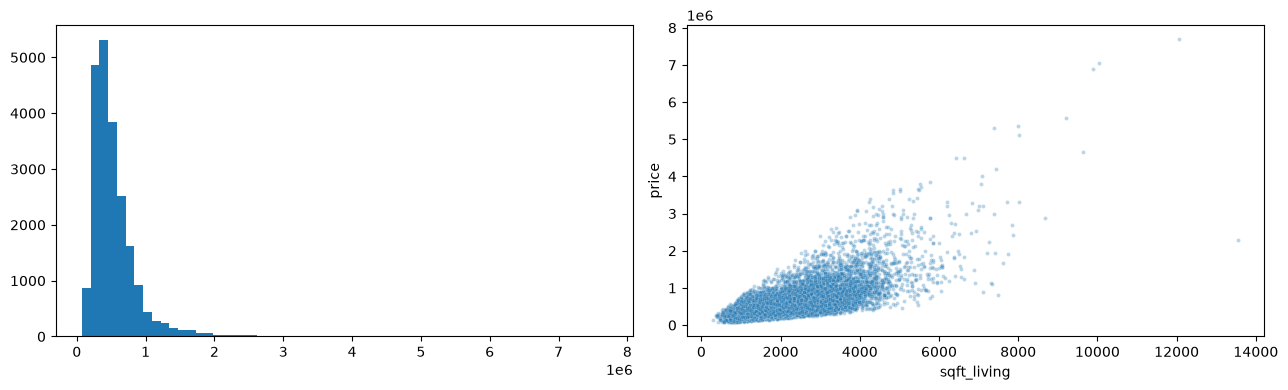

In [3]:
fig,ax=plt.subplots(1,2,figsize=(13,4)); ax[0].hist(df.price,bins=60);sns.scatterplot(data=df,x="sqft_living",y="price",s=8,alpha=.3,ax=ax[1]);
plt.tight_layout();plt.show()

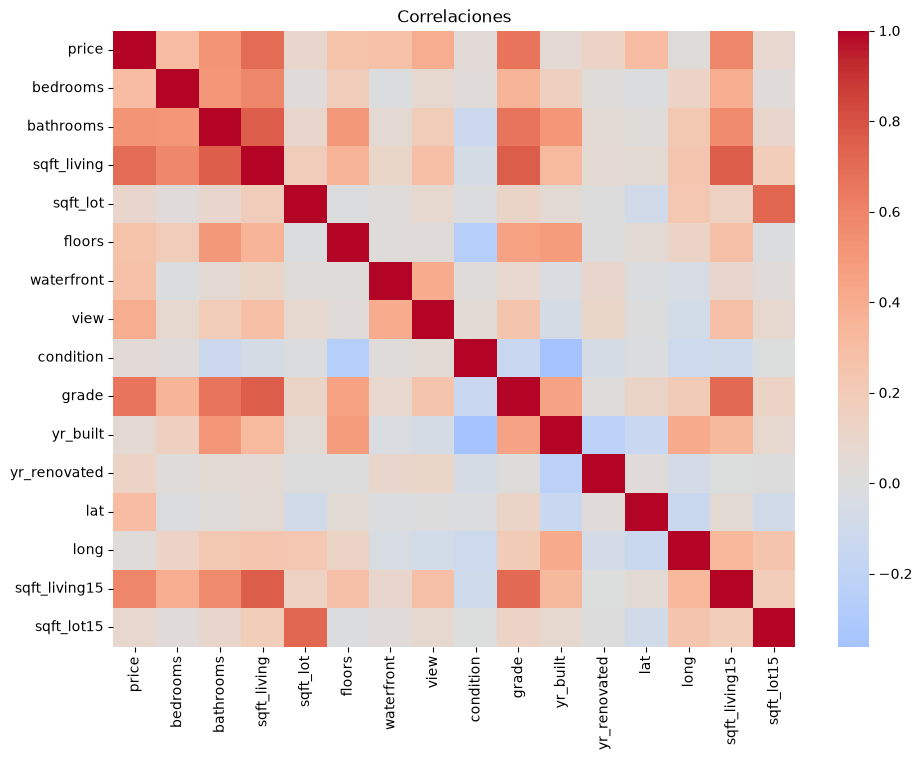

In [4]:
features = ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
plt.figure(figsize=(11,8));sns.heatmap(df[["price"]+features].corr(),cmap="coolwarm",center=0);plt.title("Correlaciones");plt.show()

## 3. Formulación matricial
Para una matriz de diseño $X$ que incluye una columna de unos, $y=X\beta+\varepsilon$. Los mínimos cuadrados minimizan $\|y-X\beta\|_2^2$. Las ecuaciones normales son $X^TX\hat\beta=X^Ty$. Si existe inversa, $\hat\beta=(X^TX)^{-1}X^Ty$. **En la práctica se utiliza** $\hat\beta=X^+y$ mediante `np.linalg.pinv`, más robusta ante singularidad o multicolinealidad.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(df[features],df["price"],test_size=0.20,random_state=42)
print("Entrenamiento:",len(X_train),"Prueba:",len(X_test))

Entrenamiento: 17290 Prueba: 4323


## 4. Selección de variables
Se aplica eliminación hacia atrás por significancia (umbral p < 0.05) **solo en entrenamiento**. Es una selección exploratoria, no una garantía causal ni de óptima generalización. Los p-valores posteriores a selección deben interpretarse con cautela. Variables correlacionadas pueden afectar la estabilidad de los coeficientes.

In [6]:
selected=features.copy(); history=[]
while True:
    temp=sm.OLS(y_train,sm.add_constant(X_train[selected],has_constant="add")).fit()
    p=temp.pvalues.drop("const",errors="ignore")
    worst=p.idxmax(); history.append({"variable":worst,"p_value":float(p.max()),"variables_restantes":len(selected)})
    if p.max() <= 0.05: break
    selected.remove(worst)
print("Variables finales:",selected)
display(pd.DataFrame(history))

Variables finales: ['bedrooms', 'bathrooms', 'sqft_living', 'floors', 'waterfront', 'view', 'condition', 'grade', 'yr_built', 'yr_renovated', 'lat', 'long', 'sqft_living15', 'sqft_lot15']


,variable,p_value,variables_restantes
0,sqft_lot,0.107041,15
1,floors,0.000227,14


## 5. Estimación matricial explícita y reporte automatizado

In [7]:
A_train=sm.add_constant(X_train[selected],has_constant="add").to_numpy(); A_test=sm.add_constant(X_test[selected],has_constant="add").to_numpy()
beta=np.linalg.pinv(A_train)@y_train.to_numpy()
modelo=sm.OLS(y_train,sm.add_constant(X_train[selected],has_constant="add")).fit()
comparacion=pd.DataFrame({"variable":["intercepto"]+selected,"beta_matricial":beta,"beta_statsmodels":modelo.params.values,"p_valor":modelo.pvalues.values})
display(comparacion);print(modelo.summary())

,variable,beta_matricial,beta_statsmodels,p_valor
0,intercepto,-3.159715e+07,-3.159715e+07,9.542371e-75
1,bedrooms,-3.307805e+04,-3.307805e+04,1.079231e-55
2,bathrooms,4.173000e+04,4.173000e+04,4.307697e-31
3,sqft_living,1.667711e+02,1.667711e+02,0.000000e+00
4,floors,1.316124e+04,1.316124e+04,2.272484e-04
5,waterfront,5.725708e+05,5.725708e+05,3.189733e-182
6,view,4.792585e+04,4.792585e+04,2.064916e-92
7,condition,2.729336e+04,2.729336e+04,5.823895e-26
8,grade,9.810219e+04,9.810219e+04,0.000000e+00
9,yr_built,-2.546809e+03,-2.546809e+03,3.149435e-215


                            OLS Regression Results                            
Dep. Variable:                  price   R-squared:                       0.694
Model:                            OLS   Adj. R-squared:                  0.694
Method:                 Least Squares   F-statistic:                     2802.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        11:50:40   Log-Likelihood:            -2.3556e+05
No. Observations:               17290   AIC:                         4.712e+05
Df Residuals:                   17275   BIC:                         4.713e+05
Df Model:                          14                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const          -3.16e+07   1.72e+06    -18.381

## 6. Ecuación final e interpretación
Cada coeficiente representa el cambio esperado en USD al incrementar una unidad de su variable, manteniendo las demás constantes. Las variables `waterfront`, `view`, `condition` y `grade` se tratan numéricamente en este modelo base: ello impone una estructura lineal que conviene examinar.

In [8]:
ecuacion=f"precio_estimado = {beta[0]:,.4f}"
for v,b in zip(selected,beta[1:]): ecuacion+=f" {b:+,.4f}*{v}"
print(ecuacion)

precio_estimado = -31,597,153.8432 -33,078.0502*bedrooms +41,729.9985*bathrooms +166.7711*sqft_living +13,161.2359*floors +572,570.8048*waterfront +47,925.8463*view +27,293.3611*condition +98,102.1946*grade -2,546.8086*yr_built +21.6531*yr_renovated +545,875.5969*lat -81,274.7890*long +30.0372*sqft_living15 -0.2266*sqft_lot15


## 7. Bondad de ajuste y validación fuera de muestra
El $R^2$ indica la fracción de variación explicada, el $R^2$ ajustado penaliza predictores, y MAE/RMSE cuantifican errores en USD. El conjunto de prueba no participa en selección ni ajuste.

In [9]:
y_pred=A_test@beta; y_pred_auto=modelo.predict(sm.add_constant(X_test[selected],has_constant="add"))
metricas=pd.Series({"R2_entrenamiento":r2_score(y_train,A_train@beta),"R2_ajustado_entrenamiento":modelo.rsquared_adj,"R2_prueba":r2_score(y_test,y_pred),"MAE_prueba_USD":mean_absolute_error(y_test,y_pred),"RMSE_prueba_USD":np.sqrt(mean_squared_error(y_test,y_pred)),"diferencia_maxima_metodos":np.max(np.abs(y_pred-y_pred_auto))})
display(metricas.to_frame("valor"))

,valor
R2_entrenamiento,0.694261
R2_ajustado_entrenamiento,0.694013
R2_prueba,0.694658
MAE_prueba_USD,128195.576268
RMSE_prueba_USD,214850.209668
diferencia_maxima_metodos,0.000000


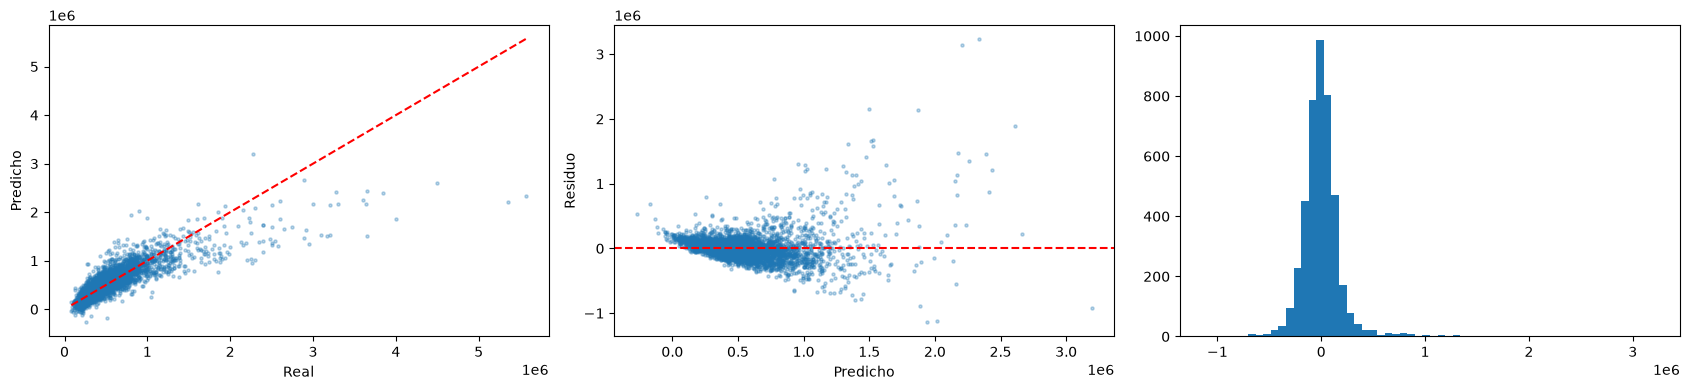

In [10]:
residuos=y_test.to_numpy()-y_pred
fig,axs=plt.subplots(1,3,figsize=(17,4));axs[0].scatter(y_test,y_pred,s=5,alpha=.3);
axs[0].plot([y_test.min(),y_test.max()],[y_test.min(),y_test.max()],"r--");axs[0].set(xlabel="Real",ylabel="Predicho");
axs[1].scatter(y_pred,residuos,s=5,alpha=.3);axs[1].axhline(0,color="r",ls="--");axs[1].set(xlabel="Predicho",ylabel="Residuo");
axs[2].hist(residuos,bins=60);plt.tight_layout();
plt.show()

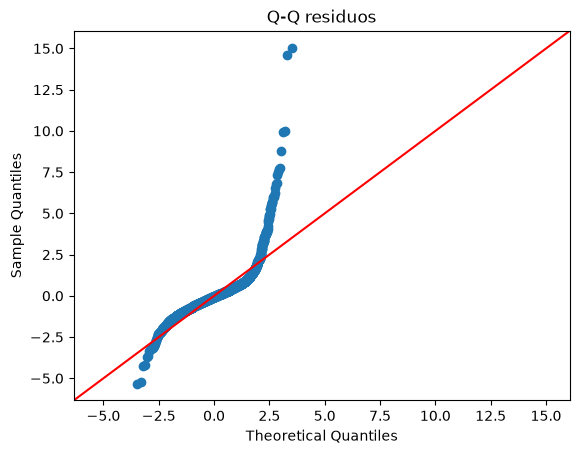

Condición de X: 34329273.815590814


In [11]:
fig=sm.qqplot(residuos,line="45",fit=True);plt.title("Q-Q residuos");plt.show()
print("Condición de X:",np.linalg.cond(A_train))

## 8. Conclusiones
El método matricial por pseudoinversa y Statsmodels deben producir estimaciones equivalentes dentro de tolerancias numéricas. El rendimiento debe juzgarse prioritariamente con R², MAE y RMSE de prueba. La correlación entre superficie, calidad y otras variables, la heterocedasticidad y los valores extremos limitan la interpretación causal y pueden deteriorar las predicciones. Una mejora posterior sería codificar las variables ordinales/categóricas, explorar transformaciones de precio, regularización y validación cruzada.

In [12]:
print("Variables retenidas:",", ".join(selected)); print("R² prueba:",round(metricas["R2_prueba"],4)); print("RMSE USD:",round(metricas["RMSE_prueba_USD"],2))
comparacion.to_csv("coeficientes_regresion.csv",index=False);metricas.to_csv("metricas_regresion.csv");print("Archivos CSV exportados")

Variables retenidas: bedrooms, bathrooms, sqft_living, floors, waterfront, view, condition, grade, yr_built, yr_renovated, lat, long, sqft_living15, sqft_lot15
R² prueba: 0.6947
RMSE USD: 214850.21
Archivos CSV exportados
